# Practical 5 — Lasso and Ridge Regression (Regularised Linear Models)

**Aim:** Reduce over-fitting and handle correlated features by *penalising large coefficients*. Compare OLS, **Ridge (L2)**
and **Lasso (L1)** with train/test split and k-fold cross-validation using **MSE** and **R²**.

**Dataset:** Diabetes dataset (10 correlated features, 442 rows).

**Idea** (λ is called `alpha` in scikit-learn):
* OLS: minimise Σ(y − ŷ)²
* **Ridge:** minimise Σ(y − ŷ)² + α·Σβⱼ² → *shrinks* all coefficients towards 0 (never exactly 0).
* **Lasso:** minimise (1/2n)Σ(y − ŷ)² + α·Σ|βⱼ| → shrinks *and sets some coefficients exactly to 0* (automatic feature selection).

Because the penalty depends on the size of the coefficients, **features must be standardised first**.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from sklearn.linear_model import LinearRegression, Ridge, Lasso, RidgeCV, LassoCV
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures

pd.set_option("display.precision", 4)
# Lasso with very small alpha on 65 correlated features may need many iterations; hide the harmless convergence warnings
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

## Evaluation helpers (shared by all regression practicals)
* **MSE** = mean((y - ŷ)²) – average squared error (lower is better)
* **R²** = 1 - SS_res / SS_tot – fraction of the variance of *y* explained by the model (1 is perfect, 0 = no better than predicting the mean)
* `kfold_regression` – manual **k-fold cross-validation**; each fold is held out once as the test set.

In [2]:
from sklearn.base import clone
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import KFold


def regression_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return pd.Series({"MSE": mse, "RMSE": np.sqrt(mse), "R2": r2_score(y_true, y_pred)})


def kfold_regression(model, X, y, k=5, seed=42, verbose=True):
    """K-fold CV. Returns (per-fold table, mean/std summary)."""
    X, y = np.asarray(X), np.asarray(y)
    kf = KFold(n_splits=k, shuffle=True, random_state=seed)
    rows = []
    for fold, (tr, te) in enumerate(kf.split(X), start=1):
        m = clone(model).fit(X[tr], y[tr])                 # fresh, untrained copy each fold
        r = regression_metrics(y[te], m.predict(X[te]))
        r.name = f"Fold {fold}"
        rows.append(r)
        if verbose:
            print(f"Fold {fold}: train={len(tr)}, test={len(te)}, MSE={r['MSE']:.2f}, R2={r['R2']:.4f}")
    folds = pd.DataFrame(rows)
    return folds, pd.DataFrame({"mean": folds.mean(), "std": folds.std()})

## Step 1 — Load data, split and standardise

In [3]:
df = load_diabetes(as_frame=True).frame
X_df, y_s = df.drop(columns="target"), df["target"]
X, y = X_df.values, y_s.values
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler().fit(X_train)            # learn mean/std from TRAIN only (no leakage)
Xs_train, Xs_test = scaler.transform(X_train), scaler.transform(X_test)
print("Train:", X_train.shape, "Test:", X_test.shape)
print("Scaled train means ≈ 0:", Xs_train.mean(axis=0).round(6))
print("Scaled train stds  = 1:", Xs_train.std(axis=0).round(6))

Train: (353, 10) Test: (89, 10)
Scaled train means ≈ 0: [ 0.  0. -0.  0. -0. -0.  0.  0.  0. -0.]
Scaled train stds  = 1: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


## Step 2 — Ridge by hand (closed form)
With centred data the Ridge solution is **β = (XᵀX + αI)⁻¹ Xᵀy**. The extra `αI` is added to the diagonal:
it makes the matrix well-conditioned (stable even with correlated features) and shrinks β.
1. Centre X (already done by the scaler) and y.
2. Form XᵀX + αI.
3. Solve for β.
4. Intercept = mean(y) (because X is centred).

In [4]:
alpha = 10.0
yc = y_train - y_train.mean()
A = Xs_train.T @ Xs_train
print("Step 2.1  XᵀX diagonal (≈ n =", len(Xs_train), "):", np.diag(A).round(1)[:3], "...")
beta_ridge = np.linalg.solve(A + alpha * np.eye(A.shape[0]), Xs_train.T @ yc)
print("Step 2.2  manual Ridge β:", beta_ridge.round(3))

ridge = Ridge(alpha=alpha).fit(Xs_train, y_train)
print("Step 2.3  sklearn Ridge β:", ridge.coef_.round(3))
print("Identical:", np.allclose(beta_ridge, ridge.coef_))

Step 2.1  XᵀX diagonal (≈ n = 353 ): [353. 353. 353.] ...
Step 2.2  manual Ridge β: [  1.931 -11.028  25.606  16.304 -12.934   0.538  -6.125   8.569  22.749
   2.918]
Step 2.3  sklearn Ridge β: [  1.931 -11.028  25.606  16.304 -12.934   0.538  -6.125   8.569  22.749
   2.918]
Identical: True


## Step 3 — Lasso by hand (coordinate descent with soft-thresholding)
Lasso has no closed form. scikit-learn cycles through the coefficients one at a time:
1. Start with β = 0.
2. For feature j compute the partial residual correlation ρⱼ = (1/n) xⱼᵀ(y − Σ_{k≠j} xₖβₖ).
3. Update βⱼ = **S(ρⱼ, α)** where the *soft-threshold* S(ρ, α) = sign(ρ)·max(|ρ| − α, 0).
   If |ρⱼ| ≤ α the coefficient becomes **exactly 0** – that is how Lasso drops features.
4. Repeat sweeps until the coefficients stop changing.

In [5]:
def soft_threshold(rho, a):
    return np.sign(rho) * np.maximum(np.abs(rho) - a, 0.0)

def lasso_cd(X, y, alpha, n_iter=500, verbose=False):
    n, p = X.shape
    beta = np.zeros(p)
    for it in range(n_iter):
        beta_old = beta.copy()
        for j in range(p):
            r_j = y - X @ beta + X[:, j] * beta[j]        # residual with feature j's contribution removed
            rho = X[:, j] @ r_j / n
            beta[j] = soft_threshold(rho, alpha) / (X[:, j] @ X[:, j] / n)
        if verbose and it < 3:
            print(f"  sweep {it + 1}: β = {beta.round(2)}")
        if np.max(np.abs(beta - beta_old)) < 1e-8:
            if verbose: print(f"  converged after {it + 1} sweeps")
            break
    return beta

alpha_l = 2.0
print("Manual coordinate descent:")
beta_lasso = lasso_cd(Xs_train, yc, alpha_l, verbose=True)
lasso = Lasso(alpha=alpha_l, max_iter=100000, tol=1e-12).fit(Xs_train, y_train)   # tight tolerance so both solvers stop at the same optimum
print("\nmanual  Lasso β:", beta_lasso.round(3))
print("sklearn Lasso β:", lasso.coef_.round(3))
print("Identical:", np.allclose(beta_lasso, lasso.coef_, atol=1e-3))
print("Coefficients set exactly to zero:", list(X_df.columns[np.isclose(lasso.coef_, 0)]))

Manual coordinate descent:
  sweep 1: β = [ 13.32  -0.    42.68  11.65  -0.21  -1.69 -11.12   0.9    9.04  -0.33]
  sweep 2: β = [  0.    -5.98  32.82  16.32  -0.    -1.81 -12.86   1.75  15.07   0.  ]
  sweep 3: β = [  0.    -8.1   27.08  16.15  -0.    -2.87 -12.9    1.75  18.21   0.4 ]
  converged after 39 sweeps



manual  Lasso β: [  0.     -7.426  26.143  14.736  -4.066  -0.    -10.871   0.     21.504
   1.467]
sklearn Lasso β: [  0.     -7.426  26.143  14.736  -4.066  -0.    -10.871   0.     21.504
   1.467]
Identical: True
Coefficients set exactly to zero: ['age', 's2', 's4']


## Step 4 — Effect of α: coefficient paths
α = 0 is plain OLS; larger α → stronger shrinkage. Ridge coefficients decay smoothly; Lasso coefficients hit zero one by one.

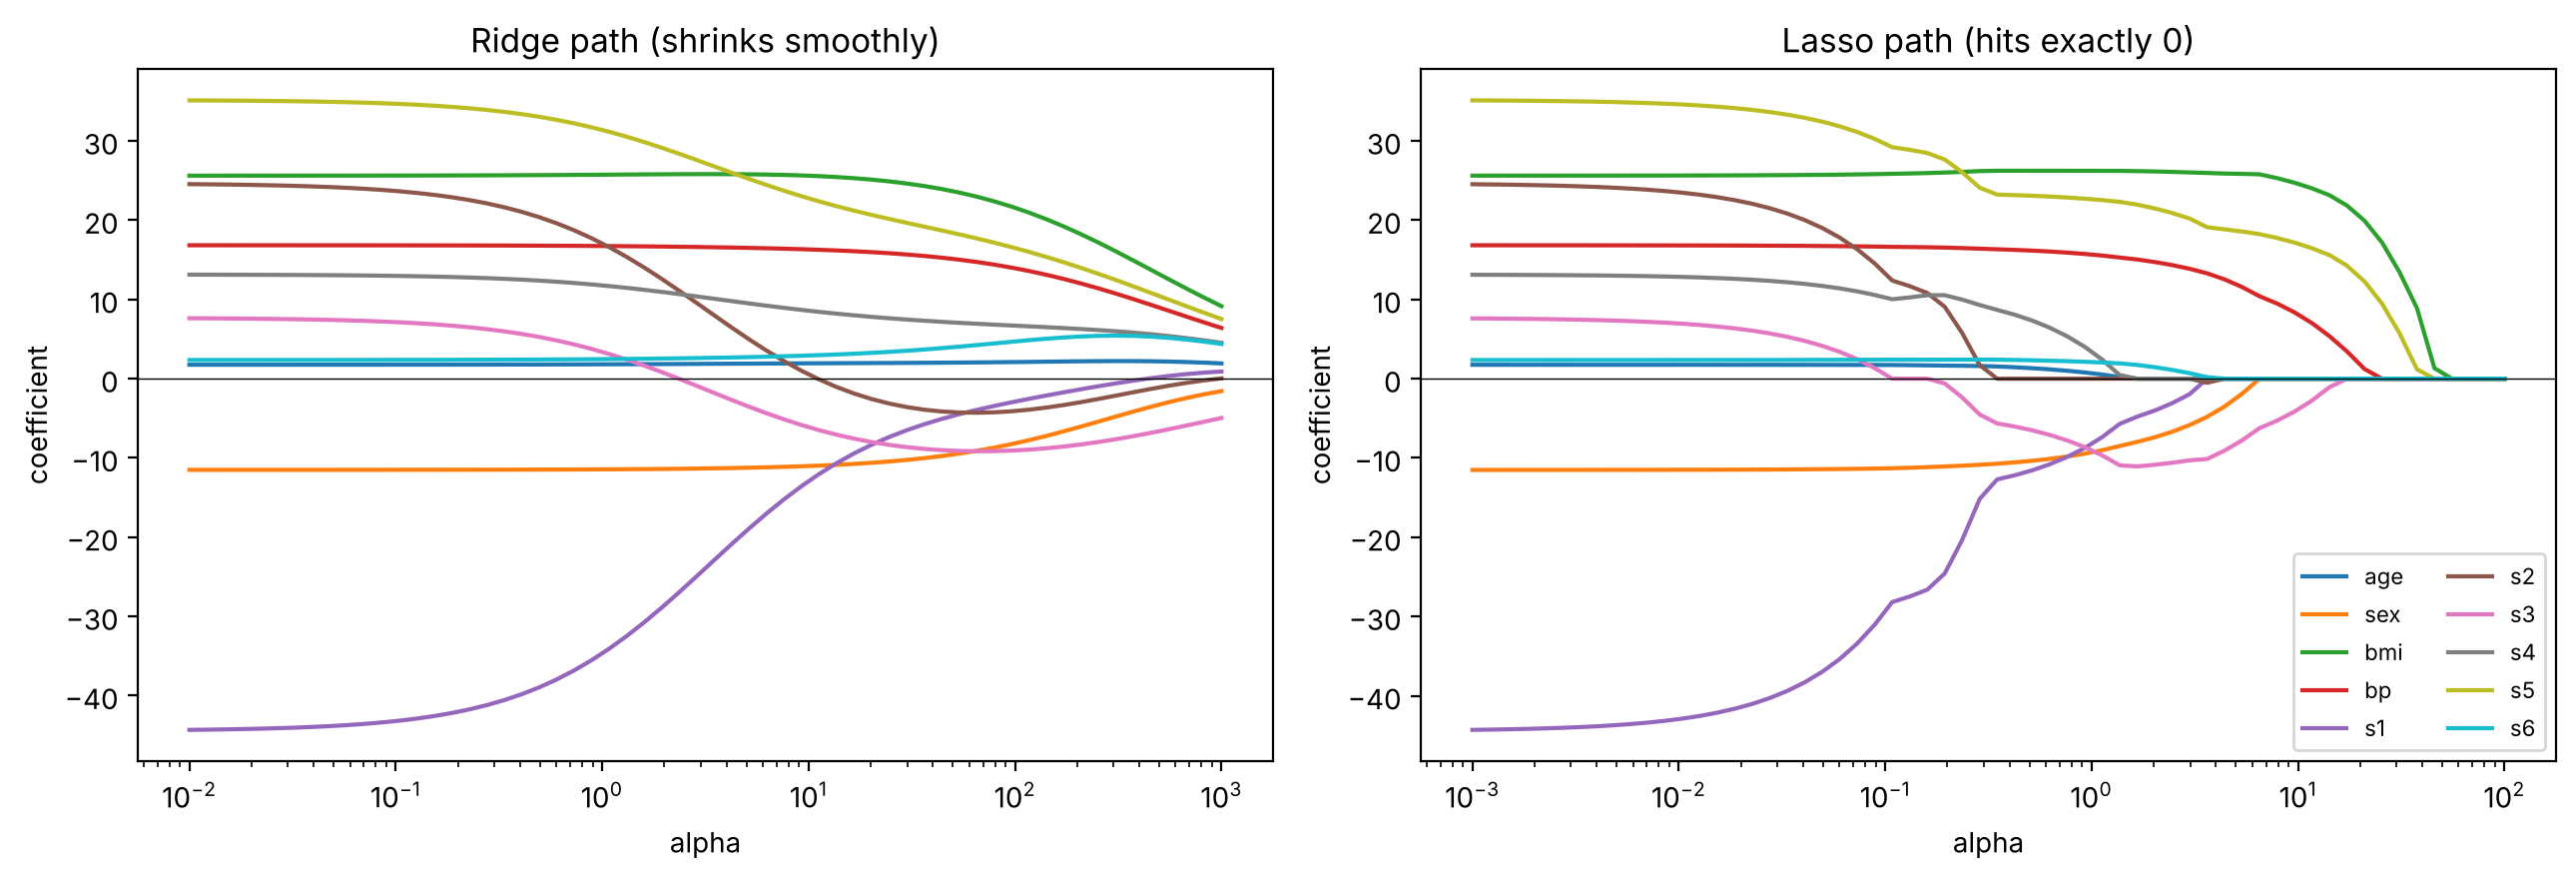

In [6]:
alphas = np.logspace(-2, 3, 60)
ridge_path = np.array([Ridge(alpha=a).fit(Xs_train, y_train).coef_ for a in alphas])
lasso_path = np.array([Lasso(alpha=a / 10, max_iter=20000).fit(Xs_train, y_train).coef_ for a in alphas])

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for j, name in enumerate(X_df.columns):
    ax[0].plot(alphas, ridge_path[:, j], label=name)
    ax[1].plot(alphas / 10, lasso_path[:, j], label=name)
ax[0].set(xscale="log", xlabel="alpha", ylabel="coefficient", title="Ridge path (shrinks smoothly)")
ax[1].set(xscale="log", xlabel="alpha", ylabel="coefficient", title="Lasso path (hits exactly 0)")
ax[1].legend(ncol=2, fontsize=8)
for a in ax: a.axhline(0, color="k", lw=0.5)
plt.tight_layout(); plt.show()

## Step 5 — Choosing α by cross-validation
`RidgeCV` / `LassoCV` try a grid of α values with k-fold CV *inside the training set* and keep the one with the lowest
validation error. The test set is never touched.

Best Ridge alpha: 44.9843
Best Lasso alpha: 1.5264


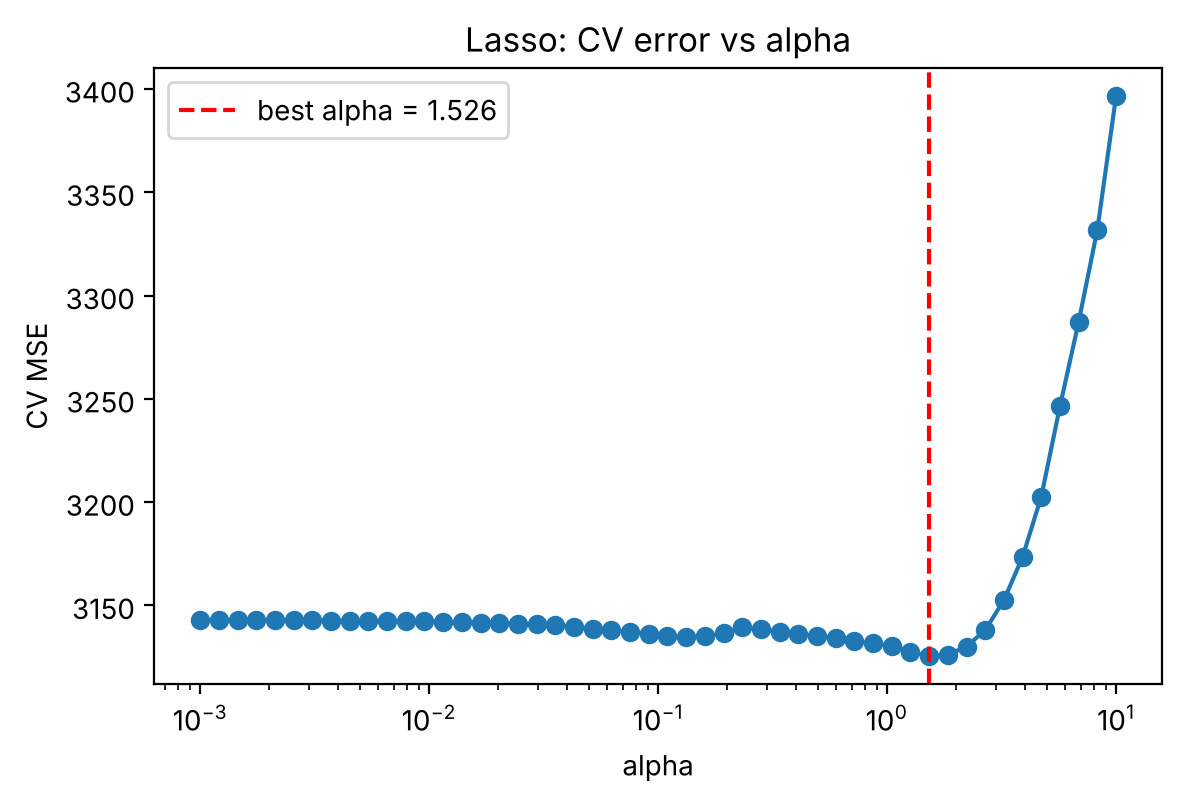

In [7]:
ridge_cv = RidgeCV(alphas=np.logspace(-3, 3, 50), cv=5).fit(Xs_train, y_train)
lasso_cv = LassoCV(alphas=np.logspace(-3, 1, 50), cv=5, max_iter=20000, random_state=0).fit(Xs_train, y_train)
print("Best Ridge alpha:", round(ridge_cv.alpha_, 4))
print("Best Lasso alpha:", round(lasso_cv.alpha_, 4))

mean_mse = lasso_cv.mse_path_.mean(axis=1)
plt.figure(figsize=(6.5, 4))
plt.plot(lasso_cv.alphas_, mean_mse, "o-")
plt.axvline(lasso_cv.alpha_, color="r", ls="--", label=f"best alpha = {lasso_cv.alpha_:.3f}")
plt.xscale("log"); plt.xlabel("alpha"); plt.ylabel("CV MSE"); plt.title("Lasso: CV error vs alpha"); plt.legend(); plt.show()

## Step 6 — Compare OLS, Ridge and Lasso
Pipelines include the scaler, so scaling is re-learned inside every CV fold.

,Train MSE,Test MSE,Test R2,CV MSE,CV R2
OLS,2868.5497,2900.1936,0.4526,3015.3817,0.4785
Ridge,2913.6979,2856.8410,0.4608,3013.9312,0.4790
Lasso,2919.8897,2801.6876,0.4712,3012.0845,0.4794


,OLS,Ridge,Lasso
age,1.75,2.01,0.01
sex,-11.51,-9.74,-8.19
bmi,25.61,23.88,26.20
bp,16.83,15.24,15.15
s1,-44.45,-5.03,-5.08
s2,24.64,-4.16,-0.00
s3,7.68,-9.04,-11.15
s4,13.14,7.16,0.00
s5,35.16,18.65,22.13
s6,2.35,3.86,1.84


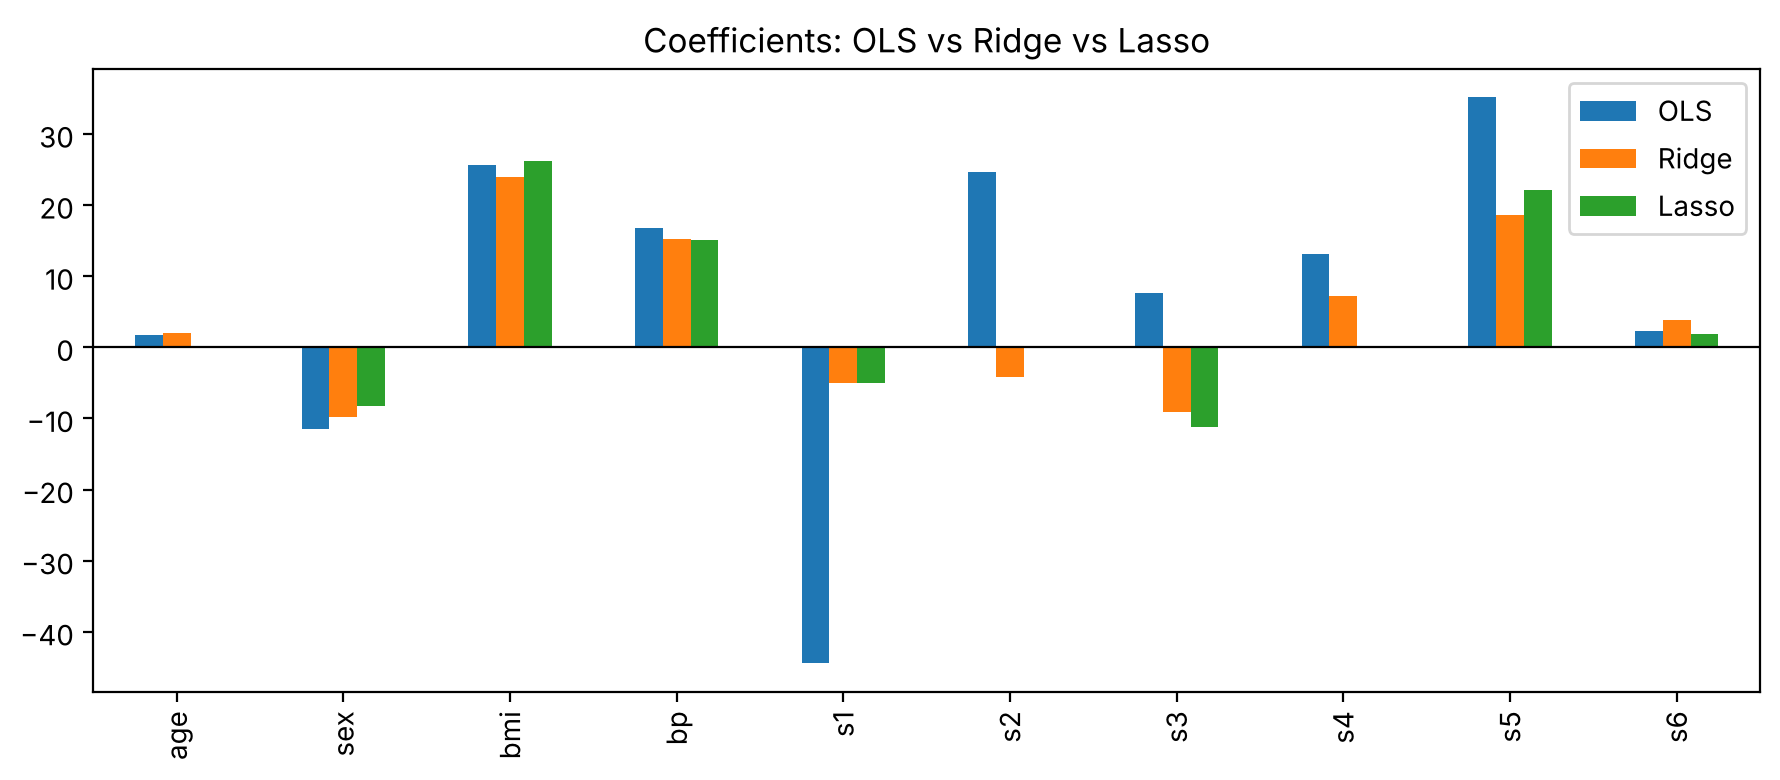

In [8]:
models = {
    "OLS": make_pipeline(StandardScaler(), LinearRegression()),
    "Ridge": make_pipeline(StandardScaler(), Ridge(alpha=ridge_cv.alpha_)),
    "Lasso": make_pipeline(StandardScaler(), Lasso(alpha=lasso_cv.alpha_, max_iter=20000)),
}
rows = {}
for name, m in models.items():
    m.fit(X_train, y_train)
    te = regression_metrics(y_test, m.predict(X_test))
    tr = regression_metrics(y_train, m.predict(X_train))
    _, cv = kfold_regression(m, X, y, k=5, verbose=False)
    rows[name] = {"Train MSE": tr["MSE"], "Test MSE": te["MSE"], "Test R2": te["R2"],
                  "CV MSE": cv.loc["MSE", "mean"], "CV R2": cv.loc["R2", "mean"]}
results = pd.DataFrame(rows).T
display(results.round(4))

coefs = pd.DataFrame({n: m[-1].coef_ for n, m in models.items()}, index=X_df.columns)
display(coefs.round(2))
coefs.plot.bar(figsize=(9, 4), title="Coefficients: OLS vs Ridge vs Lasso"); plt.axhline(0, color="k", lw=0.8)
plt.tight_layout(); plt.show()

### Detailed 5-fold CV for the Lasso model

In [9]:
folds, summary = kfold_regression(models["Lasso"], X, y, k=5)
display(folds.round(4)); display(summary.round(4))

Fold 1: train=353, test=89, MSE=2801.69, R2=0.4712
Fold 2: train=353, test=89, MSE=2765.22, R2=0.5568
Fold 3: train=354, test=88, MSE=3369.57, R2=0.3809
Fold 4: train=354, test=88, MSE=2766.73, R2=0.5889
Fold 5: train=354, test=88, MSE=3357.21, R2=0.3992


,MSE,RMSE,R2
Fold 1,2801.6876,52.9310,0.4712
Fold 2,2765.2213,52.5854,0.5568
Fold 3,3369.5741,58.0480,0.3809
Fold 4,2766.7316,52.5997,0.5889
Fold 5,3357.2077,57.9414,0.3992


,mean,std
MSE,3012.0845,321.0589
RMSE,54.8211,2.9006
R2,0.4794,0.0924


## Step 7 — Where regularisation really pays off: 65 polynomial features
Degree-2 expansion of the 10 features gives 65 correlated columns for ~350 rows. OLS over-fits; Ridge/Lasso fix it.

In [10]:
poly = PolynomialFeatures(2, include_bias=False)
P_train, P_test = poly.fit_transform(X_train), poly.transform(X_test)
big = {
    "OLS": make_pipeline(StandardScaler(), LinearRegression()),
    "Ridge": make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-1, 4, 40))),
    "Lasso": make_pipeline(StandardScaler(), LassoCV(alphas=np.logspace(-2, 1, 40), cv=5, max_iter=50000, random_state=0)),
}
out = {}
for name, m in big.items():
    m.fit(P_train, y_train)
    out[name] = {"Train MSE": mean_squared_error(y_train, m.predict(P_train)),
                 "Test MSE": mean_squared_error(y_test, m.predict(P_test)),
                 "Test R2": r2_score(y_test, m.predict(P_test))}
display(pd.DataFrame(out).T.round(3))
n_nonzero = int(np.sum(~np.isclose(big["Lasso"][-1].coef_, 0)))
print(f"Lasso kept {n_nonzero} of {P_train.shape[1]} polynomial features (the rest were set to exactly 0).")

,Train MSE,Test MSE,Test R2
OLS,2393.139,3096.028,0.416
Ridge,2698.394,2684.821,0.493
Lasso,2877.482,2584.402,0.512


Lasso kept 15 of 65 polynomial features (the rest were set to exactly 0).


### Conclusion
* With the original 10 features OLS, Ridge and Lasso perform almost the same – the data is low-dimensional and not badly over-fit.
* Ridge shrinks every coefficient and stabilises the large opposite-signed ones (s1/s2/s3…); Lasso removes weak features entirely, giving a simpler, more interpretable model.
* With 65 polynomial features OLS over-fits (train MSE ≪ test MSE); the regularised models have a much smaller gap and better test error.
* α is a hyper-parameter: pick it with cross-validation on the training data, then report performance on the untouched test set.